Housing Feature Selection

In [33]:
import kagglehub
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.compose import TransformedTargetRegressor
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
path = kagglehub.dataset_download("yasserh/housing-prices-dataset")

print("Path to dataset files:", path)


100%|██████████| 4.63k/4.63k [00:00<00:00, 2.46MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/yasserh/housing-prices-dataset/versions/1


In [6]:
df = pd.read_csv(path+"/Housing.csv")

print(df.count())
print(df.shape)
print(df.info())


price               545
area                545
bedrooms            545
bathrooms           545
stories             545
mainroad            545
guestroom           545
basement            545
hotwaterheating     545
airconditioning     545
parking             545
prefarea            545
furnishingstatus    545
dtype: int64
(545, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  par

In [34]:
X = df.drop(columns=['price'])
y = df['price']

numeric_features = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_features = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='if_binary')),
    ('scaler', StandardScaler(with_mean=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LinearRegression())
])


In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = TransformedTargetRegressor(
    regressor=clf,
    func=np.log1p,
    inverse_func=np.expm1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared Score: {r2:.2f}")


Mean Squared Error: 1483777270089.02
R-squared Score: 0.66


The initial $R^2$ is 0.66 without feature selection

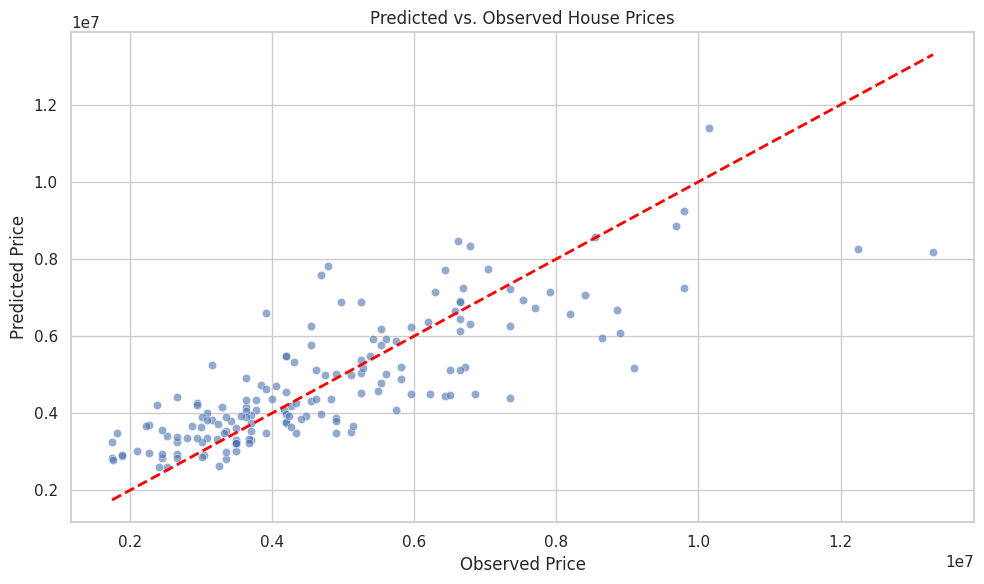

In [36]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)

max_val = max(y_test.max(), y_pred.max())
min_val = min(y_test.min(), y_pred.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2)

plt.xlabel('Observed Price')
plt.ylabel('Predicted Price')
plt.title('Predicted vs. Observed House Prices')
plt.tight_layout()

plt.show()


Linear regression with Sequential Feature Selection

In [37]:
from sklearn.feature_selection import SequentialFeatureSelector
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('feature_selector', SequentialFeatureSelector(
        estimator=LinearRegression(),
        n_features_to_select=4,
        direction='forward',
        scoring='neg_mean_squared_error',
        cv=5
    )),
    ('regressor', LinearRegression())
])

model = TransformedTargetRegressor(
    regressor=pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared Score: {r2:.2f}")

Mean Squared Error: 1974054740088.93
R-squared Score: 0.54


Sequential Feature Selection slightly reduced the $R^2$ from 0.66 to 0.54

Now using Recursive Feature Elimination

In [54]:
from sklearn.feature_selection import RFE
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('feature_selector', RFE(
        estimator=LinearRegression(),
        n_features_to_select=4,
        step=1
    )),
    ('regressor', LinearRegression())
])

model = TransformedTargetRegressor(
    regressor=pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared Score: {r2:.2f}")

Mean Squared Error: 2176370643391.05
R-squared Score: 0.49


Well, this is even wrose than sequential feature selection

What features selected?

In [56]:
fitted_pipeline = model.regressor_

final_regressor = fitted_pipeline.named_steps['regressor']

coefficients = final_regressor.coef_
intercept = final_regressor.intercept_

print(f"Final Model Coefficients: {coefficients}")
print(f"Final Model Intercept: {intercept}")

original_features = fitted_pipeline.named_steps['preprocessor'].get_feature_names_out()

rfe_mask = fitted_pipeline.named_steps['feature_selector'].support_

selected_features = original_features[rfe_mask]

print("\n--- Selected Features & Coefficients ---")
for name, coef in zip(selected_features, coefficients):
    print(f"{name}: {coef:.4f}")

Final Model Coefficients: [0.16694838 0.09431132 0.11462356 0.09813128]
Final Model Intercept: 15.239888303520866

--- Selected Features & Coefficients ---
num__area: 0.1669
num__bathrooms: 0.0943
num__stories: 0.1146
cat__basement_yes: 0.0981


Now we will use LASSO embedded method

In [57]:
from sklearn.linear_model import Lasso
from sklearn.feature_selection import SelectFromModel

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('feature_selector', SelectFromModel(
        estimator=Lasso(alpha=0.01, random_state=42),
        threshold=1e-5
    )),
    ('regressor', LinearRegression())
])

model = TransformedTargetRegressor(
    regressor=pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared Score: {r2:.2f}")


Mean Squared Error: 1485102251816.35
R-squared Score: 0.66


$R^2$ is the same as the original linear regression without selection

In [58]:
fitted_pipeline = model.regressor_

final_regressor = fitted_pipeline.named_steps['regressor']

coefficients = final_regressor.coef_
intercept = final_regressor.intercept_

original_features = fitted_pipeline.named_steps['preprocessor'].get_feature_names_out()

selector_mask = fitted_pipeline.named_steps['feature_selector'].get_support()

selected_features = original_features[selector_mask]

for name, coef in zip(selected_features, coefficients):
    print(f"{name}: {coef:.4f}")

num__area: 0.1120
num__bedrooms: 0.0169
num__bathrooms: 0.0872
num__stories: 0.0722
num__parking: 0.0409
cat__mainroad_yes: 0.0378
cat__guestroom_yes: 0.0233
cat__basement_yes: 0.0560
cat__hotwaterheating_yes: 0.0248
cat__airconditioning_yes: 0.0634
cat__prefarea_yes: 0.0433
cat__furnishingstatus_unfurnished: -0.0511


Lasso did not remove any features, possibly since they all contribute valuable information to price prediction